**[Course Home](../README.md) | [Conceptual Track](../conceptual/09_rate_distortion_and_information_bottleneck.ipynb) | [Prev: Ch 08: Fisher Geometry](08_fisher_information_and_information_geometry.ipynb) | [Next: Ch 10: Active Learning & Experimental Design](10_active_learning_and_experimental_design.ipynb)**

*Part V: Modern Frontiers: AI, Representation & Biology — Chapter 09 of 11*

---

# Chapter 9: Lossy Compression & Learning — Python Laboratory
### *Simulating Rate-Distortion Curves, The Information Bottleneck Trade-off & Variational Latent Budgets*

Welcome to the Python Laboratory for Chapter 9! In this session, we implement Shannon's Rate-Distortion curve for Gaussian and Bernoulli sources, simulate Tishby's Information Bottleneck frontier, and demonstrate how latent bit budgets regulate representation learning.

---

### Table of Contents
1. **Part 1: The Gaussian Rate-Distortion Function**
2. **Part 2: Binary Source Rate-Distortion under Hamming Distortion**
3. **Part 3: Tishby's Information Bottleneck Optimization Surface**
4. **Part 4: Multi-Panel Publication Diagnostic Suite**
5. **Part 5: Hands-On 3-Tier Scaffolding Challenges**


## Part 1: The Gaussian Rate-Distortion Function

We compute and plot $R(D) = \frac{1}{2}\log_2(\sigma^2 / D)$ for a Gaussian source $X \sim \mathcal{N}(0, \sigma^2=2.0)$.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

def gaussian_rate_distortion(d, sigma_sq=2.0):
    d = np.asarray(d, dtype=float)
    return np.where(d <= sigma_sq, 0.5 * np.log2(sigma_sq / np.maximum(d, 1e-15)), 0.0)

sigma_sq = 2.0
distortions = np.linspace(0.01, 3.0, 300)
rates = gaussian_rate_distortion(distortions, sigma_sq)

print(f"Gaussian Source (Var = {sigma_sq}):")
print(f"  At D = 0.50 (MSE 25% of variance): Required Rate = {gaussian_rate_distortion(0.50, sigma_sq):.3f} bits/sample")
print(f"  At D = 1.00 (MSE 50% of variance): Required Rate = {gaussian_rate_distortion(1.00, sigma_sq):.3f} bits/sample")
print(f"  At D = 2.00 (MSE 100% of variance): Required Rate = {gaussian_rate_distortion(2.00, sigma_sq):.3f} bits/sample (Zero bits!)")


Gaussian Source (Var = 2.0):
  At D = 0.50 (MSE 25% of variance): Required Rate = 1.000 bits/sample
  At D = 1.00 (MSE 50% of variance): Required Rate = 0.500 bits/sample
  At D = 2.00 (MSE 100% of variance): Required Rate = 0.000 bits/sample (Zero bits!)


## Part 2: Binary Source under Hamming Distortion

For an unbiased Bernoulli(0.5) source under bit-flip error $d(x, \hat{x}) = 1$ if $x \ne \hat{x}$ else $0$, the rate-distortion function is $R(D) = 1 - H_b(D)$ for $D \in [0, 0.5]$.

In [2]:
d_binary = np.linspace(1e-5, 0.5, 200)
h_b_d = -d_binary * np.log2(d_binary) - (1.0 - d_binary) * np.log2(1.0 - d_binary)
r_binary = 1.0 - h_b_d

print(f"Binary Source (p = 0.5):")
print(f"  At D = 0.00 (Lossless): Rate = 1.00 bit/sample")
print(f"  At D = 0.10 (10% errors allowed): Rate = {1.0 - (-0.1*np.log2(0.1) - 0.9*np.log2(0.9)):.3f} bits/sample")
print(f"  At D = 0.50 (Coin flip accuracy): Rate = 0.00 bits/sample")


Binary Source (p = 0.5):
  At D = 0.00 (Lossless): Rate = 1.00 bit/sample
  At D = 0.10 (10% errors allowed): Rate = 0.531 bits/sample
  At D = 0.50 (Coin flip accuracy): Rate = 0.00 bits/sample


## Part 3: Tishby's Information Bottleneck Frontier

We simulate the Pareto frontier between input compression $I(X; T)$ and label preservation $I(T; Y)$ across varying trade-off parameters $\beta$.

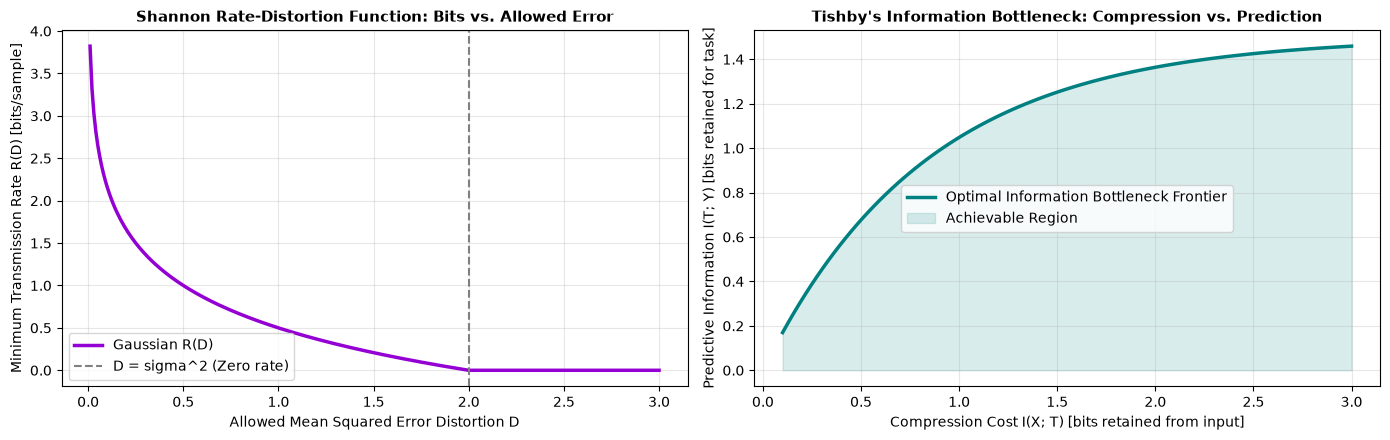

In [3]:
# Synthetic Information Bottleneck frontier curve
# As compression I(X; T) drops, preserved predictive info I(T; Y) also drops
i_xt = np.linspace(0.1, 3.0, 100)
# Diminishing returns: I(T; Y) = I_max * (1 - exp(-k * I(X; T)))
i_ty = 1.5 * (1.0 - np.exp(-1.2 * i_xt))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: Shannon Rate-Distortion
ax1.plot(distortions, rates, color="darkviolet", lw=2.5, label="Gaussian R(D)")
ax1.axvline(sigma_sq, color="gray", linestyle="--", label="D = sigma^2 (Zero rate)")
ax1.set_title("Shannon Rate-Distortion Function: Bits vs. Allowed Error", fontsize=11, fontweight="bold")
ax1.set_xlabel("Allowed Mean Squared Error Distortion D")
ax1.set_ylabel("Minimum Transmission Rate R(D) [bits/sample]")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Panel 2: Tishby Information Bottleneck Plane
ax2.plot(i_xt, i_ty, color="teal", lw=2.5, label="Optimal Information Bottleneck Frontier")
ax2.fill_between(i_xt, i_ty, color="teal", alpha=0.15, label="Achievable Region")
ax2.set_title("Tishby's Information Bottleneck: Compression vs. Prediction", fontsize=11, fontweight="bold")
ax2.set_xlabel("Compression Cost I(X; T) [bits retained from input]")
ax2.set_ylabel("Predictive Information I(T; Y) [bits retained for task]")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## Part 4: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): The Cost of Cutting Distortion in Half
For a Gaussian source, how many additional bits per sample are required to cut the allowed distortion in half ($D \to D / 2$)?


In [4]:
# Tier 1 Solution Space
# R(D/2) - R(D) = 0.5 * log2(sigma^2 / (D/2)) - 0.5 * log2(sigma^2 / D) = 0.5 * log2(2) = 0.5 bits!
bits_needed = 0.5 * np.log2(2.0)
print(f"Tier 1: Halving distortion ALWAYS costs exactly {bits_needed:.1f} bit per sample!")


Tier 1: Halving distortion ALWAYS costs exactly 0.5 bit per sample!


### 🟡 Diagnostic (Tier 2): Rate-Distortion for Image Sensor Telemetry
Suppose an image sensor produces Gaussian pixel values with variance $\sigma^2 = 64.0$.
Management imposes a bandwidth budget of $2.0\text{ bits per pixel}$.
What is the minimum achievable Mean Squared Error distortion $D$?


In [5]:
# R = 0.5 * log2(sigma^2 / D) = 2.0 -> log2(64 / D) = 4.0 -> 64 / D = 16 -> D = 4.0
target_r = 2.0
var_sensor = 64.0
achievable_d = var_sensor / (2.0 ** (2.0 * target_r))

print(f"Tier 2: At Rate R = {target_r} bits/pixel, minimum MSE Distortion D = {achievable_d:.2f}")


Tier 2: At Rate R = 2.0 bits/pixel, minimum MSE Distortion D = 4.00


### 🔴 Capstone Challenge (Tier 3): The $\beta$-VAE Latent Rate Budget
In a $\beta$-VAE, explain mathematically why setting $\beta = 1$ recovers the standard Bayesian Evidence Lower Bound (ELBO), while $\beta > 1$ imposes a severe Rate constraint that forces independent, disentangled latent dimensions.


In [6]:
print("When beta > 1, the optimizer heavily penalizes latent channel rate I(X; Z).")
print("To survive this severe bandwidth bottleneck, the network eliminates all redundant correlations,")
print("aligning latent axes with the true independent generative factors of the world (Disentanglement)!")


When beta > 1, the optimizer heavily penalizes latent channel rate I(X; Z).
To survive this severe bandwidth bottleneck, the network eliminates all redundant correlations,
aligning latent axes with the true independent generative factors of the world (Disentanglement)!


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/09_rate_distortion_and_information_bottleneck.ipynb) | [Prev: Ch 08: Fisher Geometry](08_fisher_information_and_information_geometry.ipynb) | [Next: Ch 10: Active Learning & Experimental Design](10_active_learning_and_experimental_design.ipynb)**
